# 00 — Gymnasium basics, visually

This notebook is the foundation. We use a tiny six-position world so every piece of the RL loop is visible.

**Goal:** by the end, `reset()` and `step()` should feel like ordinary functions, not RL magic.


<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto">
<path d="M0,0 L8,4 L0,8 z" fill="black"/></marker></defs>
<text x="450.0" y="28" text-anchor="middle" font-size="20" font-weight="bold">The RL loop</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="15">WORLD</text><rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="15">OBSERVATION</text><rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="15">POLICY</text><rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="15">ACTION</text><rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="15">WORLD CHANGES</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="360.0" y1="82" x2="377.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="540.0" y1="82" x2="557.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="720.0" y1="82" x2="737.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/>
</svg>
</div>


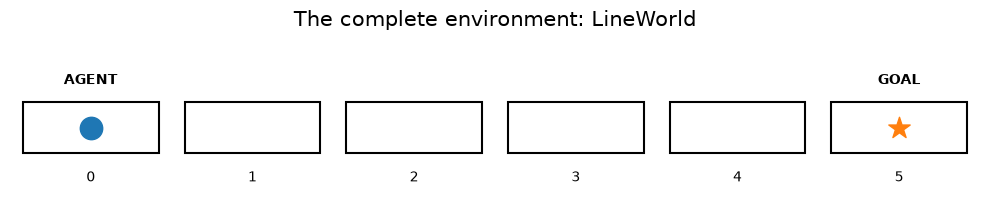

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces

repo = Path.cwd()
if repo.name == "notebooks":
    repo = repo.parent
sys.path.insert(0, str(repo))
from visuals import gridworld, pipeline, qtable_heatmap

class LineWorld(gym.Env):
    def __init__(self):
        self.action_space = spaces.Discrete(2)      # 0 LEFT, 1 RIGHT
        self.observation_space = spaces.Discrete(6)
        self.position = 0
        self.steps = 0

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.position = 0
        self.steps = 0
        return self.position, {}

    def step(self, action):
        self.steps += 1
        old = self.position
        if action == 0:
            self.position = max(0, self.position - 1)
        else:
            self.position = min(5, self.position + 1)

        terminated = self.position == 5
        truncated = self.steps >= 30
        reward = 1.0 if terminated else -0.02
        info = {"old_position": old}
        return self.position, reward, terminated, truncated, info

env = LineWorld()
fig = gridworld(position=0, goal=5, title="The complete environment: LineWorld")
plt.show()

## 1. What `reset()` actually does

`reset()` creates a fresh episode. It initializes the environment's internal state and returns the first observation.

The environment already has a true state: here, the agent is at position 0.


<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto">
<path d="M0,0 L8,4 L0,8 z" fill="black"/></marker></defs>
<text x="450.0" y="28" text-anchor="middle" font-size="20" font-weight="bold">`reset()`</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="15">reset()</text><rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="15">TRUE STATE = 0</text><rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="15">OBSERVATION = 0</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="480.0" y1="82" x2="617.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/>
</svg>
</div>


Returned observation: 0
Internal environment position: 0


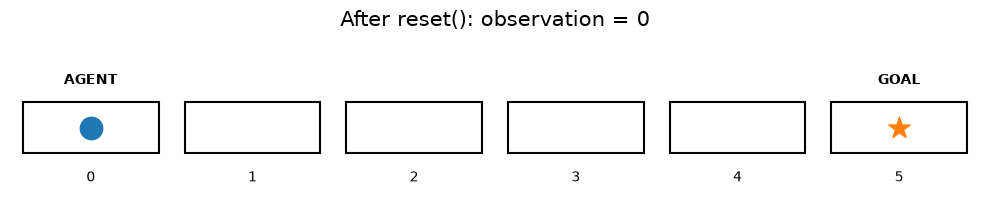

In [2]:
obs, info = env.reset(seed=1)
print("Returned observation:", obs)
print("Internal environment position:", env.position)

fig = gridworld(position=env.position, goal=5, title=f"After reset(): observation = {obs}")
plt.show()

## 2. One `step(action)`

An **action** is what the policy chooses.

Then the **environment** applies its transition rule and returns:

`next_observation, reward, terminated, truncated, info`.

RIGHT is action `1`.


<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto">
<path d="M0,0 L8,4 L0,8 z" fill="black"/></marker></defs>
<text x="450.0" y="28" text-anchor="middle" font-size="20" font-weight="bold">`step(1)`</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="15">STATE 0</text><rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="15">ACTION: RIGHT</text><rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="15">TRANSITION</text><rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="15">STATE 1</text><rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="15">REWARD -0.02</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="360.0" y1="82" x2="377.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="540.0" y1="82" x2="557.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="720.0" y1="82" x2="737.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/>
</svg>
</div>


Before: 0
Action: RIGHT
After: 1
Reward: -0.02
Terminated: False


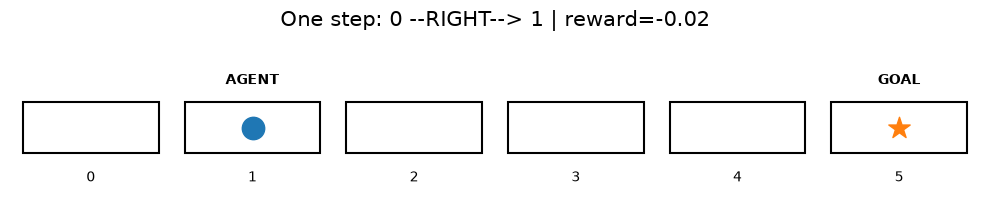

In [3]:
before = env.position
action = 1
obs, reward, terminated, truncated, info = env.step(action)
after = env.position

print("Before:", before)
print("Action:", "RIGHT")
print("After:", after)
print("Reward:", reward)
print("Terminated:", terminated)

fig = gridworld(position=after, goal=5, title=f"One step: {before} --RIGHT--> {after} | reward={reward}")
plt.show()

## 3. Policy = the chooser

A policy is simply whatever chooses the next action from the information it has.

It can be you, an `if` statement, a table, a neural network, or an LLM harness.


<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto">
<path d="M0,0 L8,4 L0,8 z" fill="black"/></marker></defs>
<text x="450.0" y="28" text-anchor="middle" font-size="20" font-weight="bold">Policy means &#x27;chooser&#x27;</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="15">OBSERVATION</text><rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="15">POLICY π</text><rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="15">ACTION</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="480.0" y1="82" x2="617.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/>
</svg>
</div>


Actions: ['LEFT', 'RIGHT', 'LEFT', 'RIGHT', 'RIGHT', 'RIGHT', 'LEFT', 'LEFT', 'LEFT', 'LEFT', 'LEFT', 'LEFT']


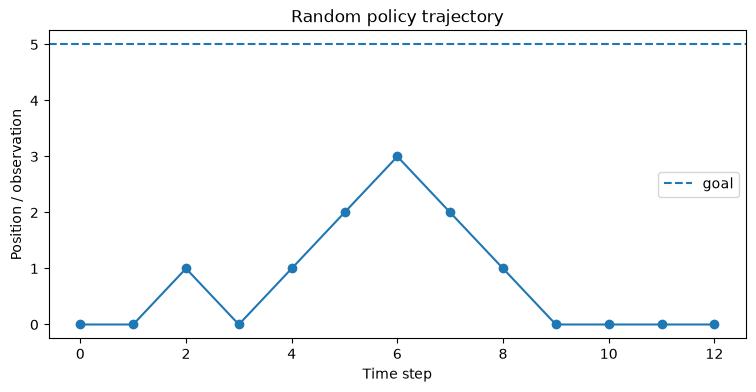

In [4]:
def random_policy(obs):
    return env.action_space.sample()

obs, _ = env.reset(seed=3)
positions = [obs]
actions = []

for t in range(12):
    a = random_policy(obs)
    actions.append(a)
    obs, reward, term, trunc, _ = env.step(a)
    positions.append(obs)
    if term or trunc:
        break

print("Actions:", ["LEFT" if a == 0 else "RIGHT" for a in actions])

plt.figure(figsize=(9,4))
plt.plot(range(len(positions)), positions, marker="o")
plt.axhline(5, linestyle="--", label="goal")
plt.xlabel("Time step")
plt.ylabel("Position / observation")
plt.title("Random policy trajectory")
plt.legend()
plt.show()

## 4. Reward does not move the world

The transition rule moves the world. Reward is a numeric evaluation signal returned **after** the action.

Here, wandering costs `-0.02` each step and reaching the goal gives `+1`.


<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto">
<path d="M0,0 L8,4 L0,8 z" fill="black"/></marker></defs>
<text x="450.0" y="28" text-anchor="middle" font-size="20" font-weight="bold">Reward is feedback</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="15">ACTION</text><rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="15">NEXT STATE</text><rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="15">REWARD</text><rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="15">LEARNING UPDATE</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="405.0" y1="82" x2="467.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="630.0" y1="82" x2="692.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/>
</svg>
</div>


Return (sum of rewards): 0.92


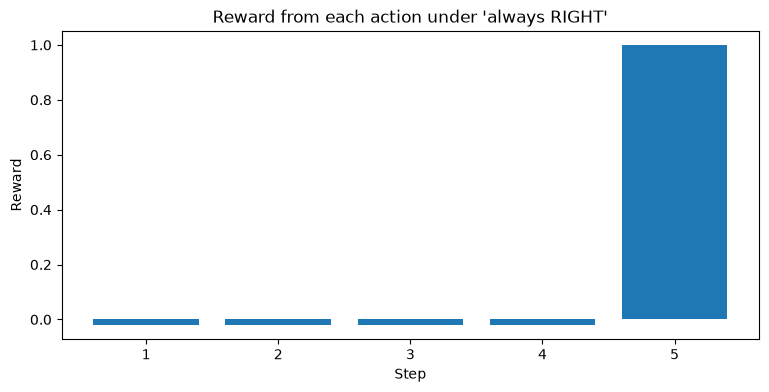

In [5]:
def always_right(obs):
    return 1

obs, _ = env.reset()
positions = [obs]
rewards = []
total = 0

while True:
    a = always_right(obs)
    obs, r, term, trunc, _ = env.step(a)
    positions.append(obs)
    rewards.append(r)
    total += r
    if term or trunc:
        break

print("Return (sum of rewards):", total)

plt.figure(figsize=(9,4))
plt.bar(range(1, len(rewards)+1), rewards)
plt.xlabel("Step")
plt.ylabel("Reward")
plt.title("Reward from each action under 'always RIGHT'")
plt.show()

## 5. Q-learning = change your opinion of actions from experience

`Q(s,a)` stores an estimate of long-term value for taking action `a` in state `s`.

Initially every Q-value is zero. Experience changes the table.


<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto">
<path d="M0,0 L8,4 L0,8 z" fill="black"/></marker></defs>
<text x="450.0" y="28" text-anchor="middle" font-size="20" font-weight="bold">Q-learning update</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="15">STATE s</text><rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="15">ACTION a</text><rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="15">REWARD r</text><rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="15">NEXT STATE s′</text><rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="15">UPDATE Q(s,a)</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="360.0" y1="82" x2="377.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="540.0" y1="82" x2="557.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="720.0" y1="82" x2="737.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/>
</svg>
</div>


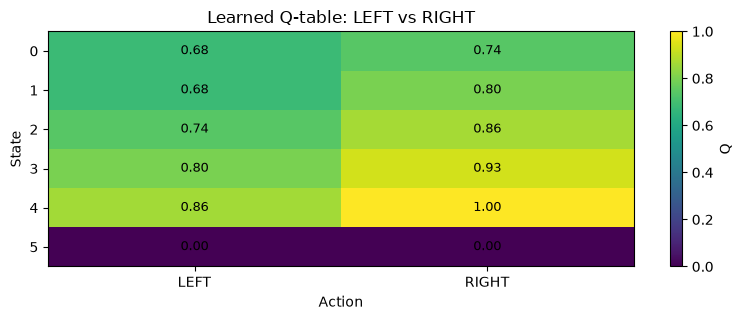

In [6]:
Q = np.zeros((6,2))
alpha = 0.2
gamma = 0.95
epsilon = 0.25
episode_returns = []

for episode in range(300):
    obs, _ = env.reset()
    total = 0.0
    while True:
        if np.random.rand() < epsilon:
            action = env.action_space.sample()
        else:
            action = int(np.argmax(Q[obs]))

        next_obs, reward, term, trunc, _ = env.step(action)
        future = 0.0 if term else np.max(Q[next_obs])
        Q[obs, action] += alpha * (reward + gamma*future - Q[obs, action])

        total += reward
        obs = next_obs
        if term or trunc:
            break
    episode_returns.append(total)

fig = qtable_heatmap(Q, title="Learned Q-table: LEFT vs RIGHT")
plt.xticks([0,1], ["LEFT","RIGHT"])
plt.show()

## 6. What learning changed

The environment did **not** learn. LineWorld's rules stayed fixed.

The **policy-producing Q-values** changed, so later the chooser prefers actions that historically led to better return.


<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto">
<path d="M0,0 L8,4 L0,8 z" fill="black"/></marker></defs>
<text x="450.0" y="28" text-anchor="middle" font-size="20" font-weight="bold">What learned?</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="15">FIXED ENVIRONMENT</text><rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="15">EXPERIENCE</text><rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="15">Q VALUES CHANGE</text><rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="15">POLICY CHANGES</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="405.0" y1="82" x2="467.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="630.0" y1="82" x2="692.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/>
</svg>
</div>


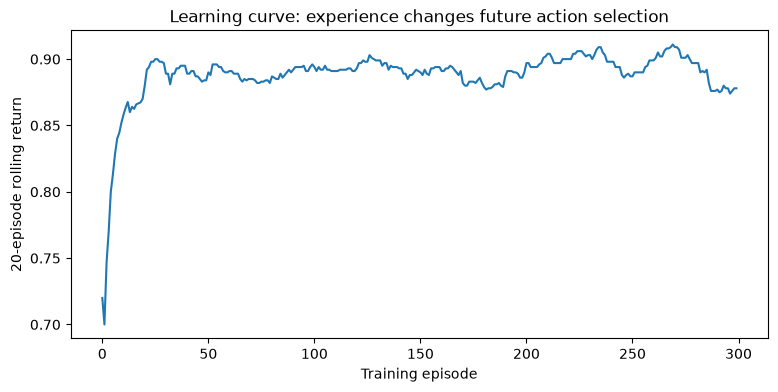

Greedy learned policy:
state 0 -> RIGHT
state 1 -> RIGHT
state 2 -> RIGHT
state 3 -> RIGHT
state 4 -> RIGHT


In [7]:
plt.figure(figsize=(9,4))
plt.plot(pd.Series(episode_returns).rolling(20, min_periods=1).mean())
plt.xlabel("Training episode")
plt.ylabel("20-episode rolling return")
plt.title("Learning curve: experience changes future action selection")
plt.show()

print("Greedy learned policy:")
for s in range(5):
    print(f"state {s} ->", "RIGHT" if np.argmax(Q[s]) == 1 else "LEFT")

## Memorize this before moving on

**Environment reacts. Policy chooses. Reward grades. Learning changes future choosing.**

Next, Toy Pong keeps the same loop but makes the state multidimensional.


<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto">
<path d="M0,0 L8,4 L0,8 z" fill="black"/></marker></defs>
<text x="450.0" y="28" text-anchor="middle" font-size="20" font-weight="bold">One loop, many problems</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="15">ENVIRONMENT</text><rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="15">STATE/OBS</text><rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="15">POLICY</text><rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="15">ACTION</text><rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="15">REWARD</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="360.0" y1="82" x2="377.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="540.0" y1="82" x2="557.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="720.0" y1="82" x2="737.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/>
</svg>
</div>
